In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display the first five rows
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [2]:
# Check missing values in each column
print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [3]:
# Identify columns containing missing values
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [4]:
# Convert pickup and dropoff columns to datetime
df["pickup"] = pd.to_datetime(df["pickup"], errors="coerce")
df["dropoff"] = pd.to_datetime(df["dropoff"], errors="coerce")

# Remove rows missing critical information
df = df.dropna(subset=["pickup", "fare", "distance"])

# Fill missing numerical values using median
numerical_columns = df.select_dtypes(include="number").columns

for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values using mode
categorical_columns = df.select_dtypes(
    include=["object", "category", "string"]
).columns

for col in categorical_columns:
    if df[col].isnull().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

# Check missing values after handling
print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


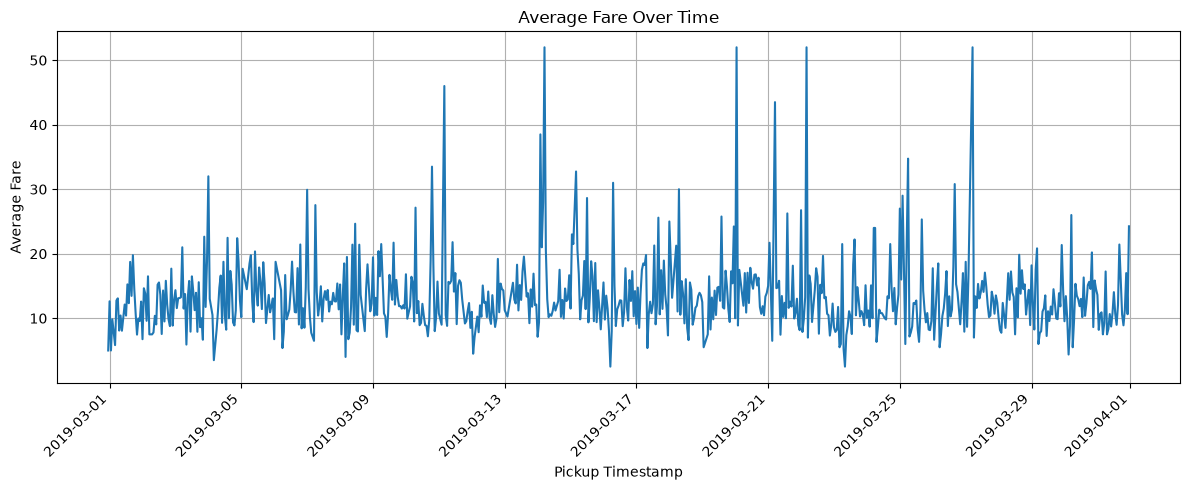

In [5]:
# Sort data by pickup timestamp
df = df.sort_values("pickup")

# Calculate average fare for each hour
hourly_fare = (
    df.set_index("pickup")["fare"]
    .resample("h")
    .mean()
    .dropna()
)

# Plot line chart
hourly_fare.plot(kind="line", figsize=(12, 5))

plt.title("Average Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Average Fare")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

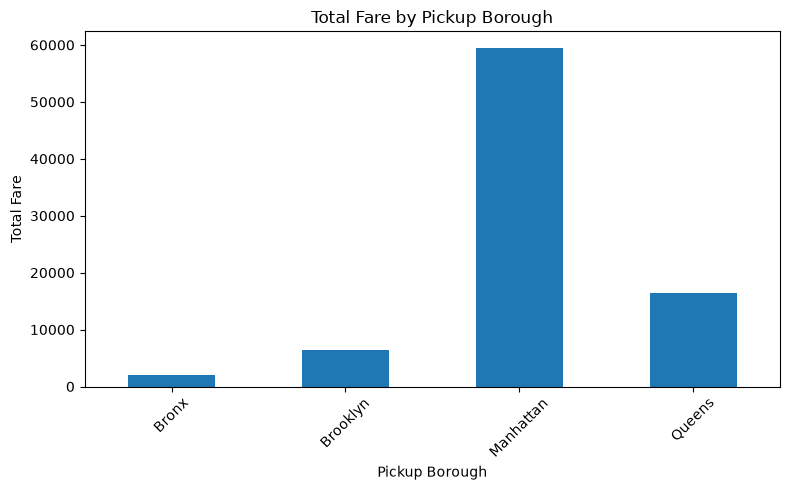

In [6]:
# Group by pickup borough and calculate total fare
borough_fare = df.groupby(
    "pickup_borough", observed=True
)["fare"].sum()

# Plot bar chart
borough_fare.plot(kind="bar", figsize=(8, 5))

plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

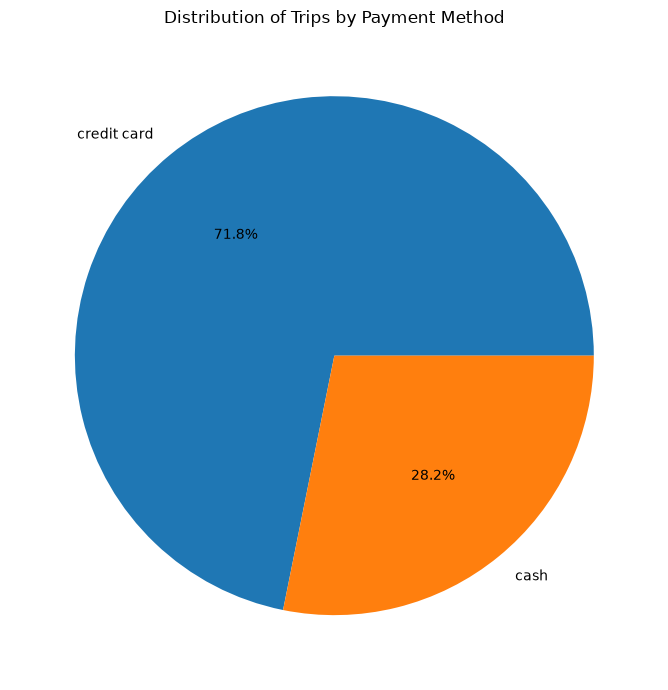

In [7]:
# Count trips by payment method
payment_counts = df["payment"].value_counts()

# Plot pie chart
payment_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7)
)

plt.title("Distribution of Trips by Payment Method")
plt.ylabel("")
plt.tight_layout()
plt.show()

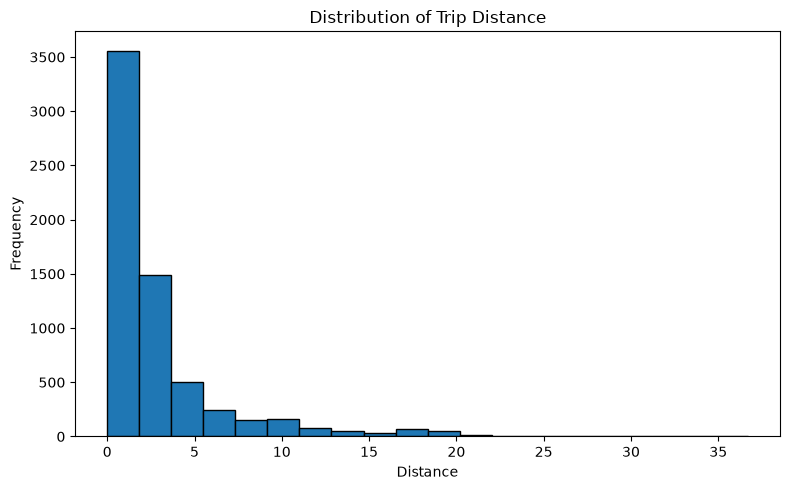

In [8]:
# Plot histogram
df["distance"].plot(
    kind="hist",
    bins=20,
    figsize=(8, 5),
    edgecolor="black"
)

plt.title("Distribution of Trip Distance")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

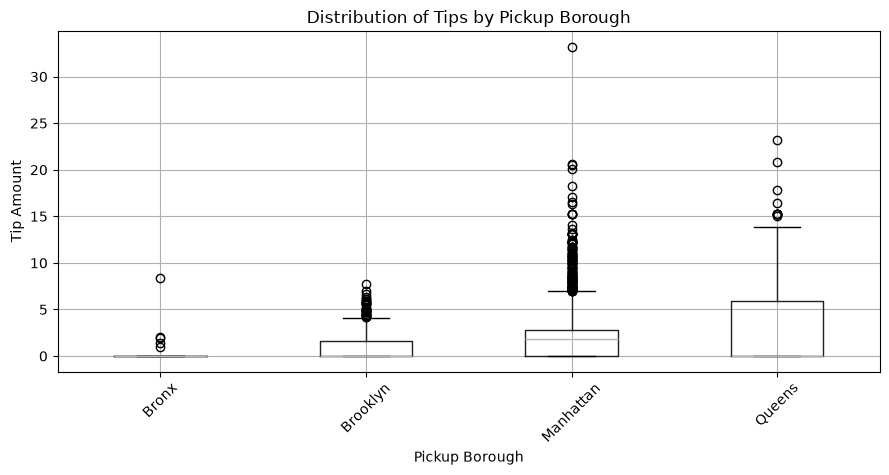

In [9]:
# Plot box plot
df.boxplot(
    column="tip",
    by="pickup_borough",
    figsize=(9, 5)
)

plt.title("Distribution of Tips by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

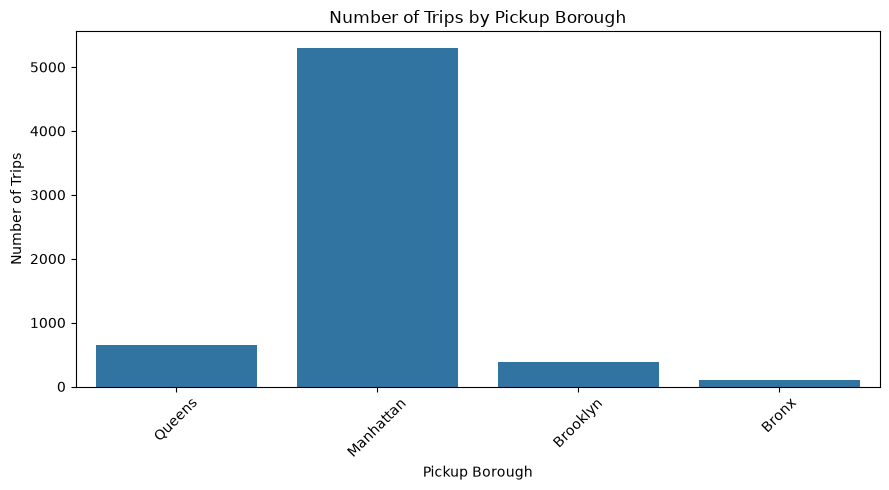

In [10]:
# Plot count plot
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="pickup_borough")

plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

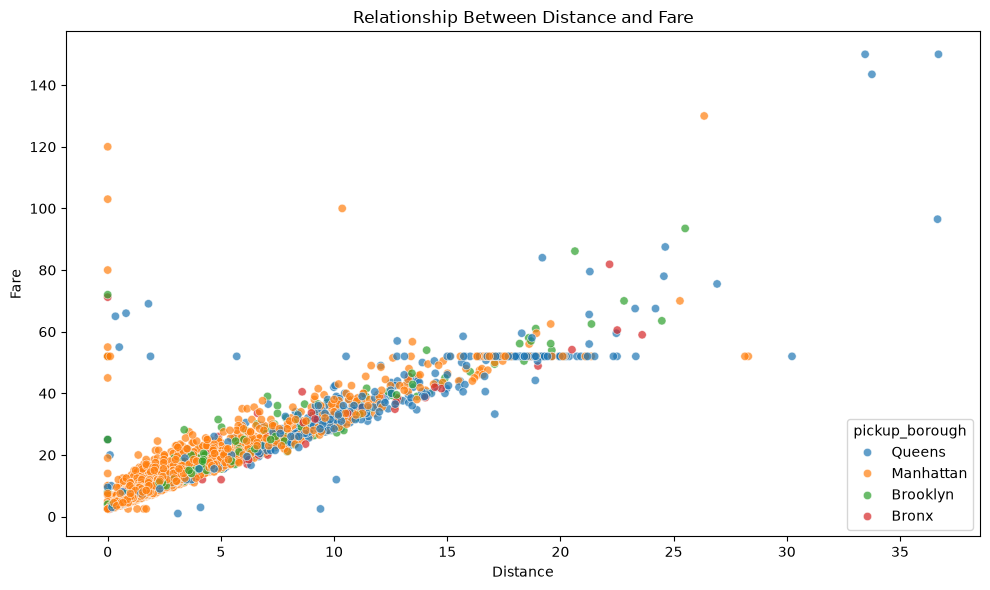

In [11]:
# Plot scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough",
    alpha=0.7
)

plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

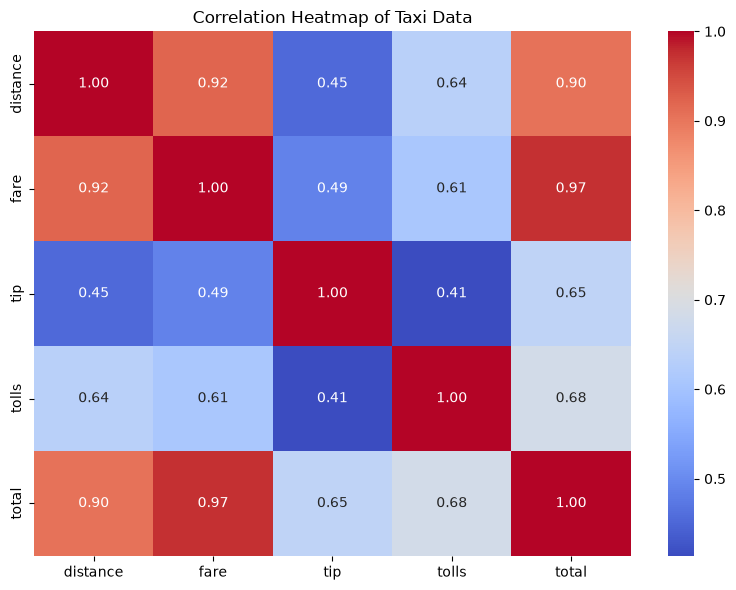

In [12]:
# Select numerical columns
numerical_data = df[
    ["distance", "fare", "tip", "tolls", "total"]
]

# Calculate correlation matrix
correlation_matrix = numerical_data.corr()

# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Taxi Data")
plt.tight_layout()
plt.show()

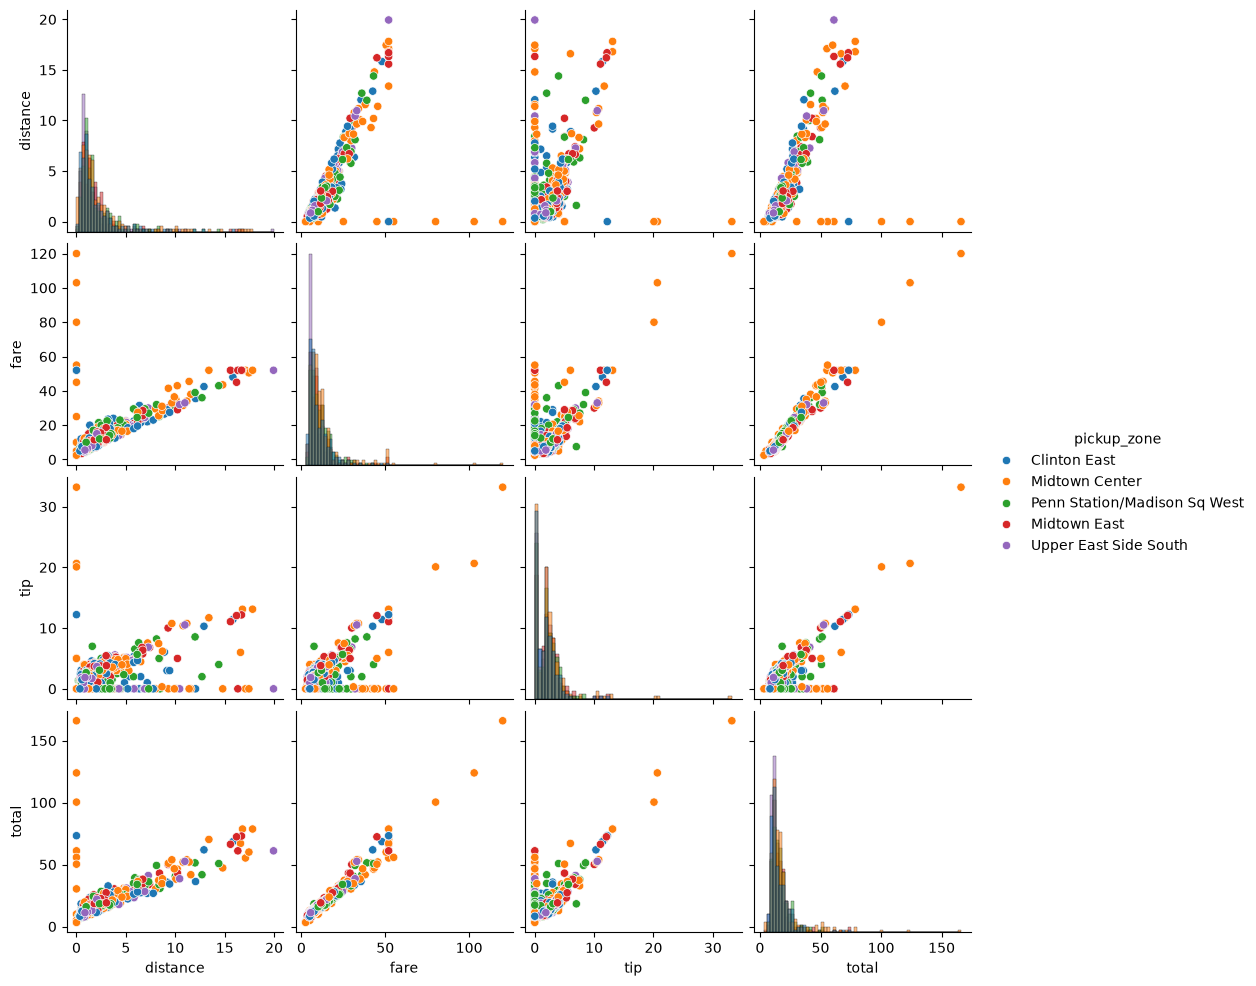

In [13]:
# Select the required columns
pair_data = df[
    ["distance", "fare", "tip", "total", "pickup_zone"]
].dropna()

# Select the five most frequent pickup zones
top_zones = pair_data["pickup_zone"].value_counts().head(5).index

pair_data = pair_data[
    pair_data["pickup_zone"].isin(top_zones)
]

# Plot pair plot
sns.pairplot(
    pair_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist"
)

plt.show()

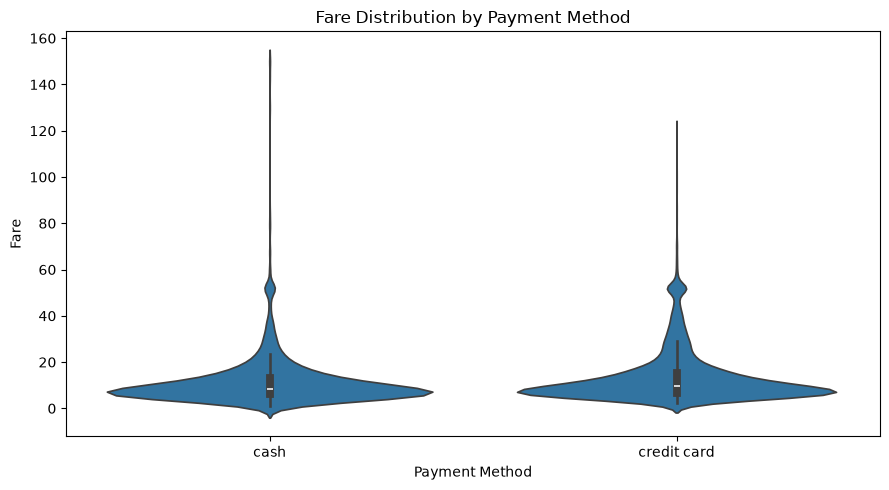

In [14]:
# Plot violin plot
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df,
    x="payment",
    y="fare"
)

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()